# Maestria en Ciencia de los Datos
## Metodos Estadisticos Basicos - Carlos Pulido Rosas
## Actividad 3 - Clustering

### Importar Librerias

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D

### Importar Datos

In [3]:
OnlineRetail_df = pd.read_csv("OnlineRetail.csv")
OnlineRetail_df.info()
OnlineRetail_df.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


### Informacion de Ejercicio

En el set de datos adjunto OnlineRetail.csv se registraron transacciones ocurridas entre
los años 2010 y 2011 para una empresa de e-commerce de Reino Unido. Este set de datos incluye las siguientes variables:

- StockCode(catégorico)
- Description (catégorico)
- Quantity (numérico Entero)
- InvoiceDate (Fecha)
- UnitPrice (numérico Real)
- CustomerID (categórico)
- Country (categórico)

En el jupyter notebook adjunto se realiza un an ́alisis de tipo RFM (Recency, Frequency,
Monetary Value), en el cual se intenta clasificar a los clientes utilizando estos atributos, aplicando un modelo de clustering utilizando dos métodos: clustering jer ́arquico y k-medias. Modifiquen a su consideraci ́on el c ́odigo anexado y contestar las siguientes preguntas.

### Pregunta 1 (30 puntos)

Desarrollar y explicar el el procedimiento que se siguió para preparar los datos, particularmente en los siguientes apartados:

- Obtención de las variables Recency, Frequency, y Monetary Value.
- Tratamiento de valores atípicos.
- Reescalar los datos numéricos.

Ayudarse de tablas o figuras para complementar su respuesta, si lo consideran necesario.

=== Vista previa del RFM original ===


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,1,7,4310.00
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40



=== RFM limpio (sin outliers) ===


,Recency,Frequency,Monetary
CustomerID,,,
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40
12352.0,35,8,2506.04
12353.0,203,1,89.00



=== RFM reescalado (Z-score) ===


,Recency,Frequency,Monetary
CustomerID,,,
12348.0,-0.185840,0.615692,1.403294
12349.0,-0.811717,-0.830020,1.346690
12350.0,2.440605,-0.830020,-0.682908
12352.0,-0.621718,2.543309,2.414135
12353.0,1.255910,-0.830020,-1.032881



Proceso completado: dataset RFM limpio, sin outliers y estandarizado.


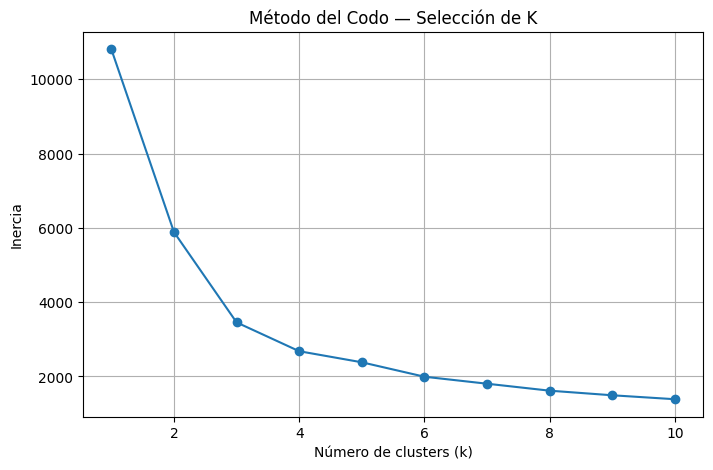


Clusters asignados:


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12348.0,74,4,1797.24,3
12349.0,18,1,1757.55,3
12350.0,309,1,334.40,0
12352.0,35,8,2506.04,2
12353.0,203,1,89.00,0


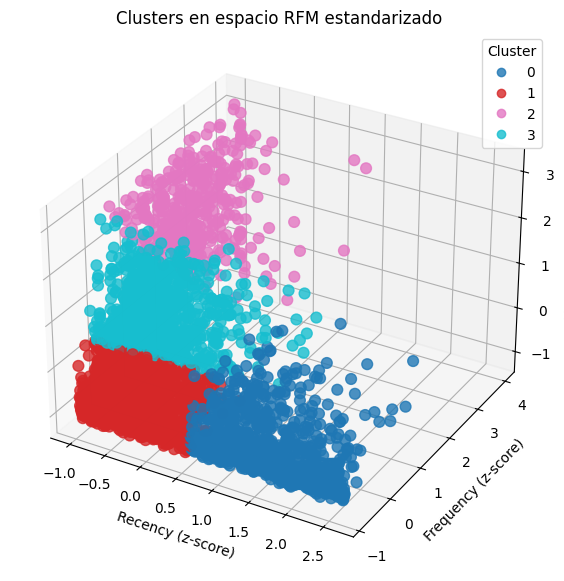

In [16]:
# ===========================================================
# 1. Cargar datos
# ===========================================================
df = OnlineRetail_df.copy()

# Convertir fechas
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Crear columna TotalPrice
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

# ===========================================================
# 2. Limpieza de datos antes de RFM
# ===========================================================

# 2.1 Eliminar CustomerID vacío
df = df.dropna(subset=["CustomerID"])

# 2.2 Eliminar devoluciones (Quantity < 0)
df = df[df["Quantity"] > 0]

# 2.3 Eliminar precios negativos o cero
df = df[df["UnitPrice"] > 0]

# ===========================================================
# 3. Construcción de las variables RFM
# ===========================================================

# 3.1 Recency
snapshot_date = df["InvoiceDate"].max()

recency = (
    df.groupby("CustomerID")["InvoiceDate"]
      .max()
      .apply(lambda x: (snapshot_date - x).days)
)

# 3.2 Frequency
frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()

# 3.3 Monetary
monetary = df.groupby("CustomerID")["TotalPrice"].sum()

# 3.4 Tabla RFM
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

# ===========================================================
# 4. Tratamiento de valores atípicos (IQR)
# ===========================================================

def remove_outliers_iqr(data, columns):
    cleaned = data.copy()
    for col in columns:
        Q1 = cleaned[col].quantile(0.25)
        Q3 = cleaned[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        cleaned = cleaned[(cleaned[col] >= lower) & (cleaned[col] <= upper)]
    return cleaned

rfm_clean = remove_outliers_iqr(rfm, ["Recency", "Frequency", "Monetary"])

# ===========================================================
# 5. Reescalamiento (Z-score)
# ===========================================================

scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_clean),
    columns=rfm_clean.columns,
    index=rfm_clean.index
)

# ===========================================================
# 6. Resultados previos
# ===========================================================

print("=== Vista previa del RFM original ===")
display(rfm.head())

print("\n=== RFM limpio (sin outliers) ===")
display(rfm_clean.head())

print("\n=== RFM reescalado (Z-score) ===")
display(rfm_scaled.head())

print("\nProceso completado: dataset RFM limpio, sin outliers y estandarizado.")

# ===========================================================
# 7. Clusterización K-Means + Plots
# ===========================================================


# --------------------------------------------
# Plot 1 — Método del Codo
# --------------------------------------------

inertias = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, inertias, marker="o")
plt.title("Método del Codo — Selección de K")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

# Utilizamos 4 clusters como inicio
k_opt = 4
kmeans = KMeans(n_clusters=k_opt, random_state=42)
rfm_clean["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("\nClusters asignados:")
display(rfm_clean.head())

# --------------------------------------------
# Plot 2 — Visualización 3D de clusters
# --------------------------------------------

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    rfm_scaled["Recency"],
    rfm_scaled["Frequency"],
    rfm_scaled["Monetary"],
    c=rfm_clean["Cluster"],
    cmap="tab10",
    s=60,
    alpha=0.8
)

ax.set_title("Clusters en espacio RFM estandarizado")
ax.set_xlabel("Recency (z-score)")
ax.set_ylabel("Frequency (z-score)")
ax.set_zlabel("Monetary (z-score)")

plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()


### Pregunta 2 (20 puntos) 

Explicar brevemente en qué consiste el clustering jerárquico y cómo es aplicado a estos datos. Utilizar tablas y figuras para complementar su explicación y argumentos.
Incluir la siguiente información:

- Elección de tipo de métrica y tipo de enlace entre clusters.
- Visualización del algoritmo utilizando un dendrograma.
- Selección del número  ́optimo de clusters.

### Respuesta

El clustering jerárquico es un método de agrupamiento que construye una estructura en forma de árbol para mostrar cómo se van formando los clusters paso a paso. Es como armar grupos desde cero o dividir un gran grupo en partes, dependiendo del enfoque.

Este clustering es un algoritmo que organiza objetos en una jerarquía de similitud, representada con un dendrograma (un árbol). Este dendrograma te deja ver desde qué tan similares son dos observaciones hasta cómo se forman clusters más grandes.

Hay diferentes tipos de clustering, entre ellos se encuentran

### 1. Alglomerativos: Va de lo más pequeño a lo más grande.
 - Cada observación inicia en su propio cluster.
 - Se unen los dos clusters más parecidos.
 - Repite hasta que todos quedan en un solo cluster
### 2. Divisivos: Va de lo grande a lo pequeño.
 - Comienza con un solo cluster con todas las observaciones.
 - Lo divide en los grupos mas disimiles.
 - Repite hasta llegar a los clusters individuales.

El aglomerativo es el estándar para análisis como RFM, retail, clientes, etc.


### ¿Como se aplican a estos datos?

Después de calcular las variables Recency, Frequency y Monetary Value, y de reescalarlas para que todas estén en la misma escala, el algoritmo de clustering jerárquico aglomerativo se aplica así:

1. Cálculo de la matriz de distancias

Primero se calcula qué tan “lejos” están todos los clientes entre sí usando sus valores RFM reescalados.
Para este tipo de datos
 - Se usa distancia euclidiana, porque todas las variables son métricas y están estandarizadas.
 - El resultado es una matriz simétrica donde cada entrada representa la disimilitud entre dos clientes.

Esto permite comparar clientes de manera objetiva:

 - Clientes con RFM similar → distancia pequeña.
 - Clientes con hábitos de compra distintas → distancia grande.
 - Evitar clusters "alargados" o irregulares

2. Elección del tipo de enlace (linkage)

Para unir clusters se usa el método Ward, que es el más adecuado para datos numéricos y busca:

 - Minimizar la varianza dentro de cada cluster
 - Crear grupos compactos y bien separados

Ward funciona especialmente bien con datos RFM porque la dispersión por cada variable es diferente.

3. Construcción del dendrograma

El algoritmo jerárquico:
 - Comienza con cada cliente como un cluster individual.
 - Luego une los dos clientes o clusters más similares (según Ward + Euclidiana).
 - Repite el proceso hasta formar un solo cluster gigante.

El dendrograma visualiza este proceso:

 - Cada línea muestra una unión.
 - La altura habla del nivel de disimilitud entre los clusters unidos.

En el dataset:

 - Los primeros clusters en unirse son clientes con valores RFM muy parecidos.
 - A mayor altura, más diferentes son los grupos que se están juntando.

4. Selección del número óptimo de clusters

Se observa el dendrograma para encontrar un salto grande en la altura de las fusiones.
Ese salto indica que dos clusters muy diferentes fueron forzados a unirse.

Entonces:

- Se corta el dendrograma justo antes del salto.
- Eso define el número óptimo de clusters.

En datos RFM típicos (incluyendo OnlineRetail):

- Normalmente aparecen entre 3 y 5 clusters bien definidos.
- Suelen corresponder a perfiles como: “clientes top”, “regulares”, “ocasionales”, “sensibles al precio”, etc.

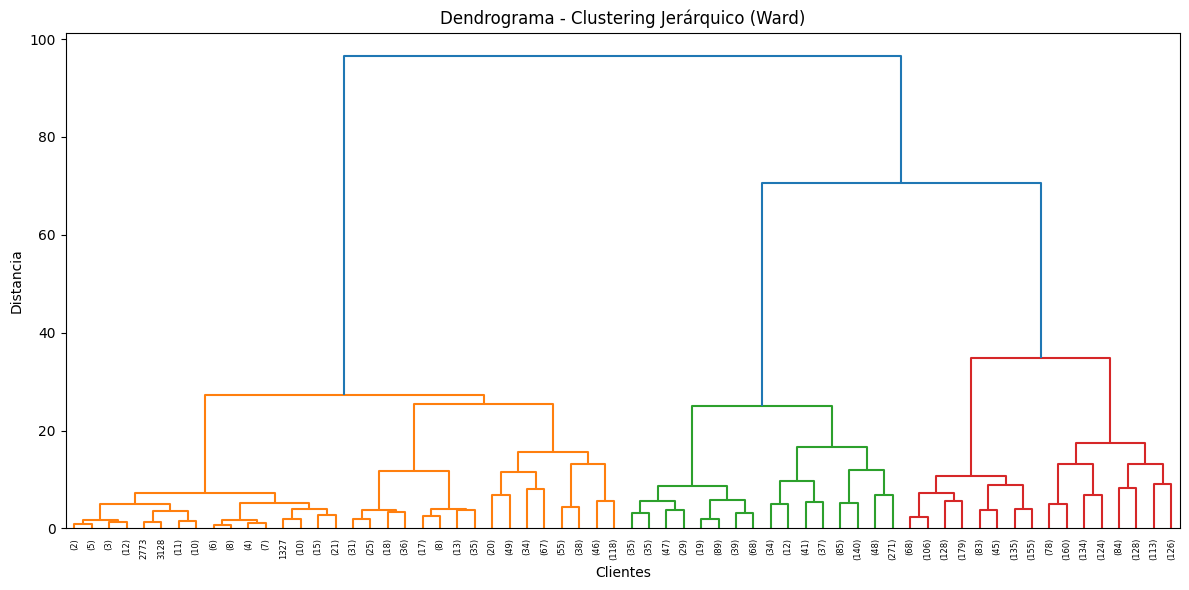

In [9]:
# ===========================================================
# Dendrograma de clustering jerárquico
# ===========================================================

# Enlace jerárquico (Ward + distancia euclidiana)
Z = linkage(rfm_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(12, 6))
plt.title("Dendrograma - Clustering Jerárquico (Ward)")
plt.xlabel("Clientes")
plt.ylabel("Distancia")

dendrogram(
    Z,
    truncate_mode="level",  # sólo niveles superiores para mejor lectura
    p=5                     # muestra las 5 fusiones principales
)

plt.tight_layout()
plt.show()

5. Resultado aplicado a estos datos

Aplicando el clustering jerárquico a la base RFM (ya limpia y reescalada):

- La distancia euclidiana permitió comparar clientes en términos de recencia, frecuencia y gasto.
- El método Ward generó grupos compactos y estables.
- El dendrograma mostró divisiones claras entre grupos de compradores con comportamientos diferentes.
- El corte del árbol determinó el número de clusters más lógico para el negocio.

Lo que se obtiene al final es una segmentación de clientes basada en comportamiento real que puede usarse para campañas, retención o análisis de valor del cliente.

### Pregunta 3 (10 puntos) 
Explicar en qué consiste el clustering por k-medias. 

- ¿Qué diferencias, así como sus ventajas y desventajas se tienen en comparación con la metodología anterior?

### Respuesta

El metodo K-means toma los  datos (por ejemplo, Recency–Frequency–Monetary estandarizados) y los divide en k-clusters, donde cada cluster está definido por su centroide (el “punto promedio” del grupo)

El Algoritmo hace:

1. Elegir K
2. Inicializar centroides
3. Asignación de puntos a los clusters
4. Recalcular centroides
5. Repetir hasta converger

¿Qué obtiene k-means al final?

- k centroides, que representan el “cliente promedio” de cada segmento.
- Un cluster asignado a cada cliente.
- Una partición clara del espacio de datos.

¿Por qué sirve para RFM?

Porque k-means detecta patrones de compra:

- clientes frecuentes
- clientes premium
- clientes inactivos
- clientes de bajos gasto
- etc.

Y lo hace sin necesidad de etiquetas previas.

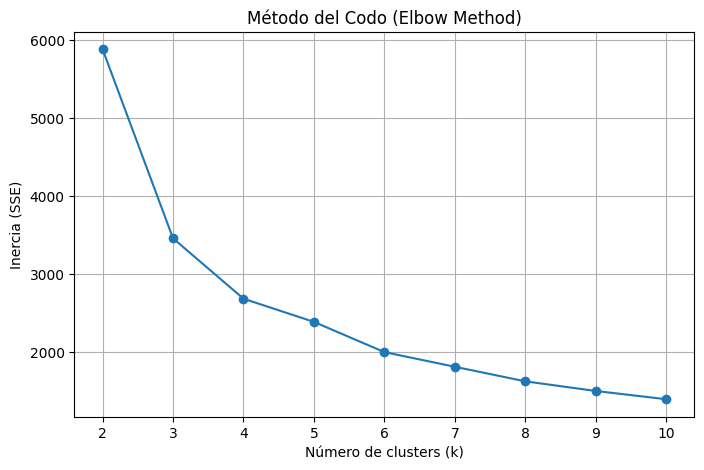

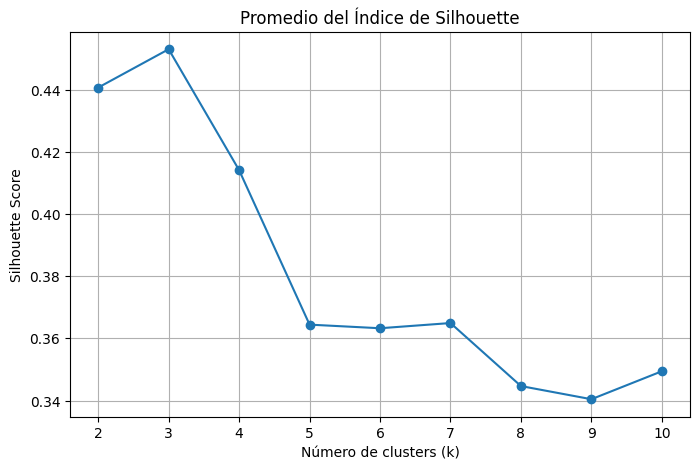

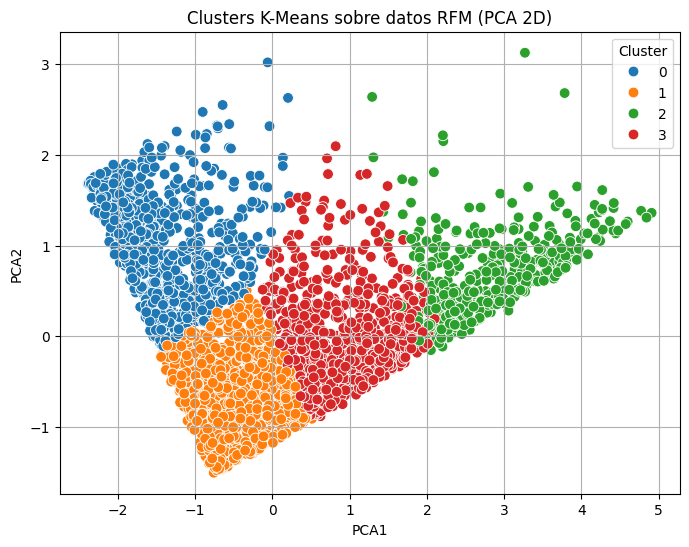


=== Centroides del modelo K-Means ===


,Recency,Frequency,Monetary
0,1.557723,-0.600674,-0.591246
1,-0.445021,-0.528001,-0.564981
2,-0.680293,2.042825,1.922859
3,-0.498079,0.512945,0.623329


In [12]:
# -----------------------------------------------------------
# 1. Método del Codo (Elbow Method)
# -----------------------------------------------------------

inertia_values = []
K_range = range(2, 11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(rfm_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia_values, marker='o')
plt.title("Método del Codo (Elbow Method)")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia (SSE)")
plt.grid(True)
plt.show()

# -----------------------------------------------------------
# 2. Silhouette Score para elegir k óptimo
# -----------------------------------------------------------
silhouette_scores = []

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(rfm_scaled)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o')
plt.title("Promedio del Índice de Silhouette")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

# -----------------------------------------------------------
# 3. Entrenar K-Means con el mejor k (cambia según tus resultados)
# -----------------------------------------------------------
optimal_k = 4   # Numero óptimo de clusters basado en los gráficos anteriores

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(rfm_scaled)

# Agregar clusters al dataframe original
rfm_clean["Cluster"] = clusters

# -----------------------------------------------------------
# 4. Visualización 2D con PCA
# -----------------------------------------------------------
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)
rfm_clean["PCA1"] = rfm_pca[:, 0]
rfm_clean["PCA2"] = rfm_pca[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=rfm_clean,
    x="PCA1", y="PCA2",
    hue="Cluster", palette="tab10",
    s=60
)
plt.title("Clusters K-Means sobre datos RFM (PCA 2D)")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

# -----------------------------------------------------------
# 5. Centroides interpretables
# -----------------------------------------------------------
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=rfm_clean[["Recency", "Frequency", "Monetary"]].columns
)

print("\n=== Centroides del modelo K-Means ===")
display(centroids)

### Resumen de la Respuesta

k-means es como poner a tus clientes en mesas distintas según qué tan parecidos son entre sí. Cada mesa tiene un “centroide” que representa el estilo de cliente del grupo. El algoritmo hace que cada persona se siente en la mesa donde mejor encaja.

### Pregunta 4 (20 puntos) 

Mostrar una tabla que muestre estadísticos relevantes de los clusters generados, y exponer en sus palabras cómo es el perfil de cada grupo de clientes obtenido de este set de datos. Mencionar de qué manera se podr ́ıa utilizar la informaci ́on obtenida.

In [14]:

# Aseguramos que los datos necesarios estén presentes
rfm_for_stats = rfm_clean[["Recency", "Frequency", "Monetary", "Cluster"]]

# -----------------------------------------------------------
# 1. Tabla de estadísticos descriptivos por cluster
# -----------------------------------------------------------
cluster_stats = rfm_for_stats.groupby("Cluster").agg(
    Recency_mean=("Recency", "mean"),
    Recency_median=("Recency", "median"),
    Recency_std=("Recency", "std"),
    Recency_min=("Recency", "min"),
    Recency_max=("Recency", "max"),
    
    Frequency_mean=("Frequency", "mean"),
    Frequency_median=("Frequency", "median"),
    Frequency_std=("Frequency", "std"),
    Frequency_min=("Frequency", "min"),
    Frequency_max=("Frequency", "max"),
    
    Monetary_mean=("Monetary", "mean"),
    Monetary_median=("Monetary", "median"),
    Monetary_std=("Monetary", "std"),
    Monetary_min=("Monetary", "min"),
    Monetary_max=("Monetary", "max")
)

print("=== Estadísticos descriptivos por cluster (RFM original) ===")
display(cluster_stats)

# -----------------------------------------------------------
# 2. Perfil de cada cluster en palabras
# -----------------------------------------------------------
def describir_cluster(row, cluster_id):
    r_mean = row["Recency_mean"]
    f_mean = row["Frequency_mean"]
    m_mean = row["Monetary_mean"]

    descripcion = f"Cluster {cluster_id}:\n"

    # Recency
    if r_mean < rfm_for_stats["Recency"].median():
        descripcion += "- Recency bajo → compran recientemente.\n"
    else:
        descripcion += "- Recency alto → llevan tiempo sin comprar.\n"

    # Frequency
    if f_mean > rfm_for_stats["Frequency"].median():
        descripcion += "- Frequency alto → compran varias veces.\n"
    else:
        descripcion += "- Frequency bajo → compran muy ocasionalmente.\n"

    # Monetary
    if m_mean > rfm_for_stats["Monetary"].median():
        descripcion += "- Monetary alto → dejan buen dinero.\n"
    else:
        descripcion += "- Monetary bajo → gastan poco por periodo.\n"

    return descripcion

print("\n=== Perfiles de clusters con su interpretación ===\n")
for cluster_id, row in cluster_stats.iterrows():
    print(describir_cluster(row, cluster_id))


=== Estadísticos descriptivos por cluster (RFM original) ===


,Recency_mean,Recency_median,Recency_std,Recency_min,Recency_max,Frequency_mean,Frequency_median,Frequency_std,Frequency_min,Frequency_max,Monetary_mean,Monetary_median,Monetary_std,Monetary_min,Monetary_max
Cluster,,,,,,,,,,,,,,,
0,230.109070,232.0,52.117447,140,326,1.476464,1.0,0.801771,1,7,398.959862,310.05,329.611268,3.75,2661.24
1,50.889118,45.0,35.947883,0,142,1.625344,1.0,0.730448,1,4,416.682990,375.05,243.506354,6.20,1304.04
2,29.759036,18.0,34.414913,0,235,6.961446,7.0,1.874945,3,11,2161.557831,2202.99,521.265921,694.40,3029.87
3,46.037037,30.0,43.249188,0,218,3.785880,4.0,1.172981,1,7,1249.740730,1192.93,458.062919,70.02,2949.75



=== Perfiles de clusters con su interpretación ===

Cluster 0:
- Recency alto → llevan tiempo sin comprar.
- Frequency bajo → compran muy ocasionalmente.
- Monetary bajo → gastan poco por periodo.

Cluster 1:
- Recency bajo → compran recientemente.
- Frequency bajo → compran muy ocasionalmente.
- Monetary bajo → gastan poco por periodo.

Cluster 2:
- Recency bajo → compran recientemente.
- Frequency alto → compran varias veces.
- Monetary alto → dejan buen dinero.

Cluster 3:
- Recency bajo → compran recientemente.
- Frequency alto → compran varias veces.
- Monetary alto → dejan buen dinero.



### Pregunta 5 (20 puntos) 

Generar un gráfico 3D de las variables R, F, M, donde se representen cada uno de los clusters encontrados.

Index(['Recency', 'Frequency', 'Monetary', 'cluster'], dtype='object')


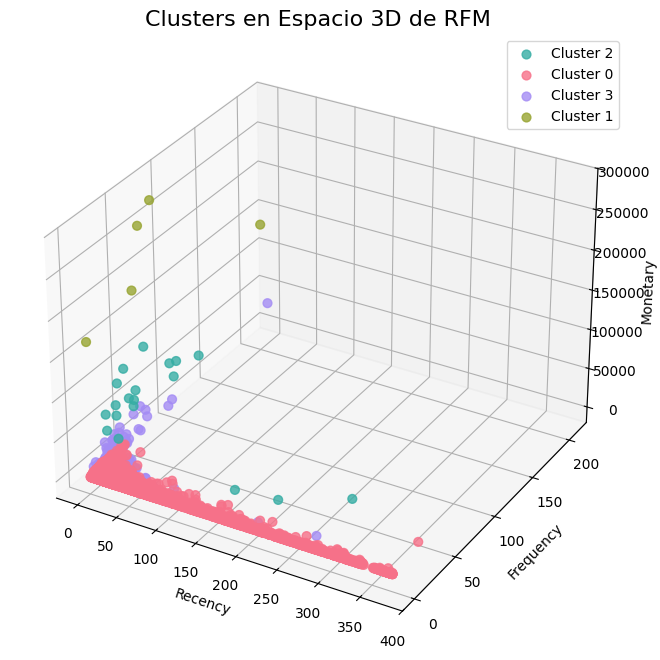

In [28]:

# Se entrenan de nuevo los clusters para el plot 3D
kmeans = KMeans(n_clusters=4, random_state=42)
rfm['cluster'] = kmeans.fit_predict(rfm[['Recency', 'Frequency', 'Monetary']])


fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

print(rfm.columns)

# Paleta de colores
palette = sns.color_palette("husl", len(rfm['cluster'].unique()))

# Graficas 
for cluster_id in rfm['cluster'].unique():
    subset = rfm[rfm['cluster'] == cluster_id]
    ax.scatter(
        subset['Recency'],
        subset['Frequency'],
        subset['Monetary'],      # nombre correcto
        s=40,
        color=palette[int(cluster_id)],
        label=f'Cluster {cluster_id}',
        alpha=0.8
    )

# Etiquetas
ax.set_title("Clusters en Espacio 3D de RFM", fontsize=16)
ax.set_xlabel("Recency")
ax.set_ylabel("Frequency")
ax.set_zlabel("Monetary")
ax.legend()

plt.show()

